# Practice Session 02: Management of networks data

In this session we will study an application of complex networks analysis to cooking. We will start with the *flavors network*, a bi-partite network connecting culinary ingredients to flavour compounds [*].

The initial dataset, prepared by [Ling Cheng in 2016](https://github.com/lingcheng99/Flavor-Network), contains three files:

* `ingredients.tsv` -- information about culinary ingredients
* `compounds.tsv` -- information about flavour compounds
* `ingredient-compound.tsv` -- flavour compounds present in each culinary ingredient
* `recipes.csv` -- ingredients used in recipes around the world (used only for extra points)

[*] Ahn, Y. Y., Ahnert, S. E., Bagrow, J. P., & Barabasi, A. L. (2011). [Flavor network and the principles of food pairing](https://doi.org/10.1038/srep00196). Scientific reports, 1(1), 1-7.

You can find this dataset in the data folder form this same github repository.

<font size="-1" color="gray">(Remove this cell when delivering.)</font>

Author: <font color="blue">Martí Pascual Barluenga</font>

E-mail: <font color="blue">marti.pascual01@estudiant.upf.edu</font>

Date: <font color="blue">5/10/2024</font>

# 0. Use a Cytoscape App (ClusterMaker2)

## 0.1. Install ClusterMaker2

Install ClusterMaker2 (``Apps > App Store``). You may be able to install it directly from a browser, or you may need to download a jar file from the [releases](https://apps.cytoscape.org/apps/clustermaker2) directory of clustermaker2, and then ``Apps > App Store > Install apps from file ...`` in the App Manager.

## 0.2. Use ClusterMaker2 to Karate Club

Use ClusterMaker2 on the Karate Club.

* Try with two different cluster algorithms in the `ClusterMaker2` plug-in. Not all the methods work: try two that do.
   * You can find a description of the algorithms used in the [ClusterMaker2 homepage](http://www.rbvi.ucsf.edu/cytoscape/clusterMaker2/)
   * You can start by running the affinity [affinity propagation](https://en.wikipedia.org/wiki/Affinity_propagation) clustering algorithm in ClusterMaker2 (Apps > ClusterMaker cluster network > Affinity Propagation Cluster ...) and seeing if that works.
      * * Once you run it, the network will have a new attribute in the nodes (in the node table you will see an attribute named ``_APCluster``)
      * Use the new attribute in the nodes for "Fill color" using a "Discrete mapping" on ``_APCluster.`` Note that with the right button you can generate a mapping out of a set of pre-defined ones.
* If you can choose an attribute in the clustering algorithm, you can choose "Edge betweenness"
   * You MUST run the network analyzer first, so you can have "Edge betweenness" as an attribute in edges
   * Use the new attributes in the nodes for "Fill color" using "Discrete mapping" on the attribute. Note that with the right button you can generate a mapping out of a set of pre-defined ones.
* Compare both obtained clusters with the actual one shown here:

![Karate Club](https://www.researchgate.net/profile/Marcus-Perry-2/publication/325719324/figure/fig1/AS:636707967889409@1528814417977/True-communities-of-Zacharys-karate-club-network.png)

<img src="Affinity propagation cluster.png">

The photo above is the final result of clustering the karate graph with the affinity propagation clustering algorithm with the atribute edge betweenes.

<img src="Labelpropagation.png">

The photo above is the final result of clustering the karate graph with the label propagation(remote) clustering algorithm with the atribute edge betweenes.

We can observe the clear similarities between the given picture and the last graph obtained when applying the label propagation algorithm. When the karate club separated, the two groups were influenced by the leaders, the president and the sensei. The same thing happens in the picture of the given graph.


*   Closeness centrality: Closeness centrality is a metric that varies depending on the total distance from a node to all other nodes. The smaller this distance is, the higher its closeness centrality. This metric is used to identify nodes that, on average, are closer to other nodes and may be important connectors in the graph.
*   Betweenness centrality: Betweenness centrality is a metric that varies depending on how often a node lies on the shortest paths between other nodes. The more a node is included in these paths, the higher its betweenness centrality. This is used to found nodes that are important in controlling the connections in the graph.

# 1. The flavors bi-partite graph

## 1.0. Examine your input files




## 1.1. Read the bipartite graph in a dataframe


The following code, which you can leave as-is, reads the ingredient-compound relationship into a dataframe.

<font size="-1" color="gray">(Remove this cell when delivering.)</font>

In [1]:
%pip install pandas
%pip install networkx
%pip install matplotlib
%pip install scipy

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


In [2]:
%cd flavors-network

[WinError 2] El sistema no puede encontrar el archivo especificado: 'flavors-network'
c:\Users\marti\OneDrive\Escritorio\PS02-u232620


c:\Users\marti\OneDrive\Escritorio\PS02-u232620\.venv\Lib\site-packages\IPython\core\magics\osm.py:393: UserWarning: This is now an optional IPython functionality, using bookmarks requires you to install the `pickleshare` library.
  bkms = self.shell.db.get('bookmarks', {})


In [3]:
# Feel free to add imports if you need them

import io
import csv
import pandas as pd
import networkx as nx

from networkx.algorithms import bipartite

import numpy as np
import matplotlib
import scipy

import itertools

from IPython.display import Image

In [4]:
# Leave this code as-is

INPUT_INGR_FILENAME = "ingredients.tsv"
INPUT_COMP_FILENAME = "compounds.tsv"
INPUT_INGR_COMP_FILENAME = "ingredient-compound.tsv"

In [5]:
# Leave this code as-is

ingredients = pd.read_csv(INPUT_INGR_FILENAME, sep="\t")
display(ingredients.head(3))

compounds = pd.read_csv(INPUT_COMP_FILENAME, sep="\t")
display(compounds.head(3))

ingr_comp = pd.read_csv(INPUT_INGR_COMP_FILENAME, sep="\t")
display(ingr_comp.head(3))


,ingredient_id,ingredient_name,ingredient_category
0,0,magnolia_tripetala,flower
1,1,calyptranthes_parriculata,plant
2,2,chamaecyparis_pisifera_oil,plant derivative


,compound_id,compound_name,compound_code
0,0,jasmone,488-10-8
1,1,5-methylhexanoic_acid,628-46-6
2,2,l-glutamine,56-85-9


,ingredient_id,compound_id
0,1392,906
1,1259,861
2,1079,673


## 1.2. Create the flavors bipartite network


Create a new dataframe named `flavors` by joining `ingredients` and `compounds`.

*Tips*:

* To [join](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.join.html) a DataFrame A and a DataFrame B using a column X, use `result = A.set_index('X').join(B.set_index('X'), how='inner')
* You will need to do two joins to solve this. First, join `ingredients` and `ingr_comp`, then join the result with `compounds`.

<font size="-1" color="gray">(Remove this cell when delivering.)</font>

In [6]:
ingredients_comp = ingredients.set_index('ingredient_id').join(ingr_comp.set_index('ingredient_id'), how='inner')
flavors = ingredients_comp.reset_index().set_index('compound_id').join(compounds.set_index('compound_id'), how='inner')
display(flavors.head(10))

,ingredient_id,ingredient_name,ingredient_category,compound_name,compound_code
compound_id,,,,,
995,0,magnolia_tripetala,flower,diacetyl,431-03-8
921,1,calyptranthes_parriculata,plant,citral_(neral),5392-40-5
1018,2,chamaecyparis_pisifera_oil,plant derivative,undecanoic_acid,112-37-8
272,3,mackerel,fish/seafood,"2,4-nonadienal",6750-03-4
275,3,mackerel,fish/seafood,lauric_acid,143-07-7
423,3,mackerel,fish/seafood,vanillin,121-33-5
424,3,mackerel,fish/seafood,2-pentylfuran,3777-69-3
282,3,mackerel,fish/seafood,"vanillin,_natural",121-33-5
972,3,mackerel,fish/seafood,3-octen-2-one,1669-44-9


In [7]:
flavors = flavors.drop(columns=['compound_code']).sort_values(by=['ingredient_name', 'compound_name']).reset_index(drop=True)
display(flavors.head(10))

,ingredient_id,ingredient_name,ingredient_category,compound_name
0,1392,abies_alba,plant,bornyl_acetate
1,1259,abies_alba_pine_needle,plant,maltol
2,1079,abies_balsamea_oil,plant derivative,myrcene
3,22,abies_canadensis,plant,bornyl_acetate
4,103,abies_concolor,plant,bornyl_acetate
5,1005,abies_sibirica,plant,bornyl_acetate
6,1005,abies_sibirica,plant,camphene
7,1005,abies_sibirica,plant,isoborneol
8,371,acacia,plant,(e)-2-hexenyl_hexanoate
9,371,acacia,plant,benzyl_acetate


In [8]:
flavors[['ingredient_name', 'ingredient_category', 'compound_name']].to_csv('flavors.tsv', sep='\t', index=False)

## 1.3. Open this bi-partite network in Cytoscape


In [9]:
# KEEP THIS CELL AS-IS

# Just adjust width/height if necessary

Image(url="flavors_rosemary.png", width=1200)

#For google colab, you can alternative use this to plot the image:
#import matplotlib.pyplot as plt
#img = plt.imread('flavors_rosemary.png')
#plt.axis('off')
#plt.imshow(img)

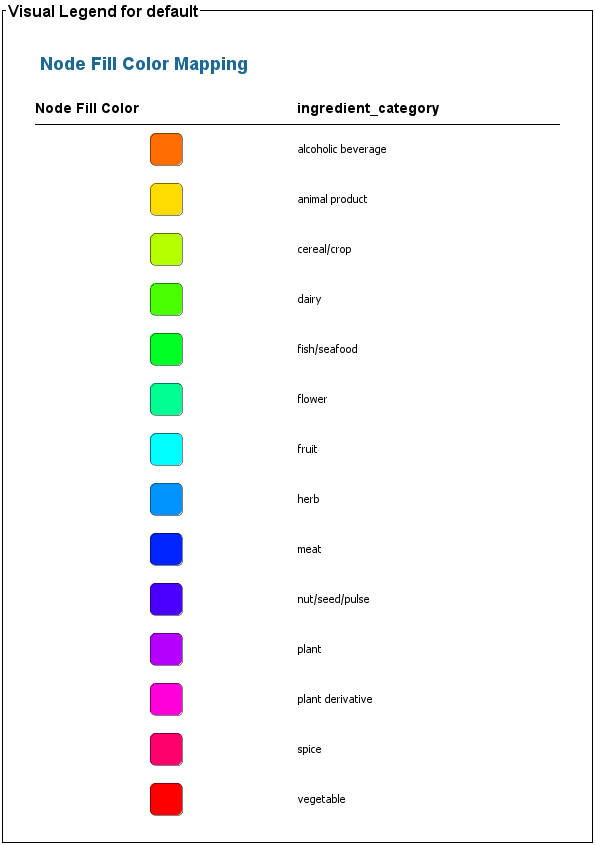

In [10]:
Image(filename='flavors_rosemary-legend.gif')

### 1.3.4 Compounds in common



In [11]:
# KEEP THIS CELL AS-IS

# Just adjust width/height if necessary

Image(url="compounds-in-common.png", width=1200)

The total nodes of the previous graph is 97, becouse we want to know the number of compounds they share, we substract two to the total. Hence, they have 95 compounds in common.From the list of nodes of degree two, we can observe that the number of compounds that contain "pyrazine" in their name is 21. Some of them are 2,3,5,6-tetramethylpyrazine and 2,3,5-trimethylpyrazine. 

# 2. The ingredient-ingredient graph

## 2.1. Create an ingredient-ingredient.gml file


In [12]:
ingredients_array = np.asarray(ingredients['ingredient_name'])
print("There are %d ingredients" % (len(ingredients_array)))

There are 1530 ingredients


In [13]:
ingredient_to_compounds = {}
for index, row in flavors.iterrows():
    ingredient = row['ingredient_name']
    compound = row['compound_name']
    if ingredient not in ingredient_to_compounds:
        ingredient_to_compounds[ingredient] = set()
    ingredient_to_compounds[ingredient].add(compound)
print("Number of keys in ingredient_to_compounds: %d" % len(ingredient_to_compounds))

Number of keys in ingredient_to_compounds: 1525


In [14]:
ingredient_ingredient = nx.Graph()
MIN_COMMON_COMPOUNDS = 75
for u, v in itertools.combinations(ingredients_array, 2):
    if u in ingredient_to_compounds and v in ingredient_to_compounds:
        common_compounds = ingredient_to_compounds[u].intersection(ingredient_to_compounds[v])
        weight = len(common_compounds)
        if weight >= MIN_COMMON_COMPOUNDS:
            ingredient_ingredient.add_edge(u, v, weight=weight)
print("The ingredient-ingredient graph has %d nodes and %d edges" %
      (ingredient_ingredient.number_of_nodes(), ingredient_ingredient.number_of_edges()))

The ingredient-ingredient graph has 152 nodes and 1647 edges


In [15]:
OUTPUT_INGR_INGR_FILENAME = 'ingredient-ingredient.gml'

In [16]:

nx.write_gml(ingredient_ingredient, OUTPUT_INGR_INGR_FILENAME)

## 2.2. Work with this file in Cytoscape

## 2.2.1. Inspect this file

## 2.2.2. Import this file into Cytoscape


In [17]:
# Change width if necessary

display(Image(url="ingr-ingr.png", width=1200))

display(Image(url="ingr-ingr-legend.gif", width=400))

Some interesting pairings in the network are apple and strawberry or strawberry with white wine. These two pairs of ingredients share a lot of ingredients in common, which can be observed by the width of the line. Trying to create a new recipe with these ingredients could result in a dish that is more likely to taste good. This graph is useful for recognizing and creating more recipes by exploring different ingredients.


<font size="+2" color="#003300">I hereby declare that, except for the code provided by the course instructors, all of my code, report, and figures were produced by myself.</font>
